# 06 — Fenótipo + conectividade

Combina o fenótipo comum às bases (idade e QI) com a conectividade AAL padronizada por instituição (notebook 05),
nas duas tarefas válidas, dentro de cada base:
- **TEA × Controle** (ABIDE I, C-PAC)
- **TDAH × Controle** (ADHD-200, Athena, com os controles recuperados)

A comparação de três classes entre bases fica de fora: a conectividade identifica o pipeline (notebook 04).

**Conjuntos de features** (`src/fusion.py`):
| Conjunto | O que entra |
|---|---|
| Fenótipo | idade, QI total, verbal, de execução e discrepância VIQ − PIQ |
| Conectividade | 6441 pares AAL (z de Fisher), padronizados por instituição |
| Fusão precoce | tudo junto num único modelo |
| Fusão tardia | um modelo para cada fonte, média das probabilidades |

**Sexo fica fora** das features: aqui as amostras não são pareadas, e a proporção de meninos difere entre casos e
controles por recrutamento (o modelo aprenderia a amostragem, não o transtorno).

**Validação:** `GroupKFold` por instituição, 5 dobras, 3 repetições. Imputação do fenótipo dentro do treino.

In [1]:
import sys
import warnings
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from connectivity import standardize_by_group
from evaluation import metrics_binary, repeated_group_cv
from fusion import make_fusion_models
from harmonize import INSTITUTION, load_adhd200

warnings.filterwarnings("ignore")
FIG = ROOT / "results" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
SEEDS = range(3)
CONJUNTOS = ["Fenótipo", "Conectividade", "Fusão precoce", "Fusão tardia"]

npz = np.load(ROOT / "data" / "processed" / "connectivity_aal.npz", allow_pickle=True)
FC = pd.DataFrame(npz["X"], index=npz["subject_id"])

coorte = pd.read_csv(ROOT / "data" / "interim" / "cohort_7_21.csv").set_index("subject_id")
abide = coorte[(coorte.release == "ABIDE_I") & coorte.index.isin(FC.index)]
adhd = load_adhd200()
adhd = adhd[adhd.diagnosis.notna() & adhd.age.between(7, 21) & adhd.subject_id.isin(FC.index)].copy()
adhd["institution"] = adhd.site.replace(INSTITUTION)
adhd = adhd.set_index("subject_id")

def fenotipo(d):
    return pd.DataFrame({"idade": d.age, "qi_total": d.fiq, "qi_verbal": d.viq, "qi_execucao": d.piq,
                         "discrep_viq_piq": d.viq - d.piq})

TAREFAS = {"TEA × Controle (ABIDE I)": (abide, "TEA"), "TDAH × Controle (ADHD-200)": (adhd, "TDAH")}
for t, (d, pos) in TAREFAS.items():
    print(f"{t}: {len(d)} sujeitos ({(d.diagnosis == pos).sum()} {pos}), {d.institution.nunique()} instituições")

TEA × Controle (ABIDE I): 732 sujeitos (345 TEA), 17 instituições
TDAH × Controle (ADHD-200): 853 sujeitos (323 TDAH), 7 instituições


### Fenótipo por grupo (médias e fração ausente)

In [2]:
linhas = []
for t, (d, pos) in TAREFAS.items():
    F = fenotipo(d).assign(grupo=d.diagnosis)
    for g, sub in F.groupby("grupo"):
        linhas.append({"tarefa": t, "grupo": g, "n": len(sub), **sub.drop(columns="grupo").mean().round(1).to_dict(),
                       "ausente_viq_piq": sub.qi_verbal.isna().mean().round(2)})
pd.DataFrame(linhas)

,tarefa,grupo,n,idade,qi_total,qi_verbal,qi_execucao,discrep_viq_piq,ausente_viq_piq
0,TEA × Controle (ABIDE I),Controle,387,13.5,109.7,110.5,106.4,3.9,0.16
1,TEA × Controle (ABIDE I),TEA,345,13.6,104.2,103.1,103.7,-0.6,0.14
2,TDAH × Controle (ADHD-200),Controle,530,12.1,113.9,115.5,110.0,5.5,0.36
3,TDAH × Controle (ADHD-200),TDAH,323,11.6,106.3,109.0,102.2,6.8,0.23


## 1. Rodar os 16 modelos em cada tarefa

In [3]:
res = {}
for t, (d, pos) in TAREFAS.items():
    F = fenotipo(d)
    C = standardize_by_group(FC.loc[d.index].to_numpy(), d.institution.to_numpy())
    X = np.hstack([F.to_numpy(), C])
    y = (d.diagnosis == pos).astype(int).to_numpy()
    g = d.institution.to_numpy()
    for (modelo, conj), est in make_fusion_models(F.shape[1], C.shape[1]).items():
        r, _ = repeated_group_cv(est, X, y, g, seeds=SEEDS, metric_fn=partial(metrics_binary, nomes=("Controle", "caso")))
        res[(t, modelo, conj)] = r
    print("ok:", t)

ok: TEA × Controle (ABIDE I)


ok: TDAH × Controle (ADHD-200)


## 2. Resultados

In [4]:
tab = pd.DataFrame({k: r.drop(columns="semente").mean() for k, r in res.items()}).T
tab.index.names = ["tarefa", "modelo", "conjunto"]
for t in TAREFAS:
    print(f"\n=== {t}: acurácia balanceada (AUC) ===")
    sub = tab.loc[t]
    acc = sub["acc_balanceada"].unstack("conjunto")[CONJUNTOS]
    auc = sub["auc"].unstack("conjunto")[CONJUNTOS]
    print((acc.round(3).astype(str) + " (" + auc.round(2).astype(str) + ")").to_string())
tab.round(3)


=== TEA × Controle (ABIDE I): acurácia balanceada (AUC) ===
conjunto                 Fenótipo Conectividade Fusão precoce  Fusão tardia
modelo                                                                     
Random Forest         0.58 (0.61)   0.61 (0.67)  0.623 (0.69)   0.61 (0.65)
Regressão logística  0.594 (0.62)  0.641 (0.69)  0.646 (0.69)  0.662 (0.71)
XGBoost              0.561 (0.59)  0.639 (0.69)  0.648 (0.71)  0.644 (0.69)
Árvore de decisão    0.573 (0.59)  0.552 (0.57)   0.585 (0.6)  0.585 (0.61)

=== TDAH × Controle (ADHD-200): acurácia balanceada (AUC) ===
conjunto                 Fenótipo Conectividade Fusão precoce  Fusão tardia
modelo                                                                     
Random Forest        0.524 (0.54)  0.493 (0.49)  0.507 (0.51)  0.521 (0.53)
Regressão logística  0.574 (0.59)  0.502 (0.49)  0.502 (0.49)   0.52 (0.53)
XGBoost              0.523 (0.51)  0.475 (0.45)  0.484 (0.48)  0.507 (0.49)
Árvore de decisão    0.544 (0.52)  0.499

acc_balanceada  \
tarefa                     modelo              conjunto                        
TEA × Controle (ABIDE I)   Regressão logística Fenótipo                0.594   
                                               Conectividade           0.641   
                                               Fusão precoce           0.646   
                                               Fusão tardia            0.662   
                           Árvore de decisão   Fenótipo                0.573   
                                               Conectividade           0.552   
                                               Fusão precoce           0.585   
                                               Fusão tardia            0.585   
                           Random Forest       Fenótipo                0.580   
                                               Conectividade           0.610   
                                               Fusão precoce           0.623   
                                               Fusão tardia            0.610   
                           XGBoost             Fenótipo                0.561   
                                               Conectividade           0.639   
                                               Fusão precoce           0.648   
                                               Fusão tardia            0.644   
TDAH × Controle (ADHD-200) Regressão logística Fenótipo                0.574   
                                               Conectividade           0.502   
                                               Fusão precoce           0.502   
                                               Fusão tardia            0.520   
                           Árvore de decisão   Fenótipo                0.544   
                                               Conectividade           0.499   
                                               Fusão precoce           0.531   
                                               Fusão tardia            0.506   
                           Random Forest       Fenótipo                0.524   
                                               Conectividade           0.493   
                                               Fusão precoce           0.507   
                                               Fusão tardia            0.521   
                           XGBoost             Fenótipo                0.523   
                                               Conectividade           0.475   
                                               Fusão precoce           0.484   
                                               Fusão tardia            0.507   

                                                              sens_caso  \
tarefa                     modelo              conjunto                   
TEA × Controle (ABIDE I)   Regressão logística Fenótipo           0.583   
                                               Conectividade      0.616   
                                               Fusão precoce      0.614   
                                               Fusão tardia       0.614   
                           Árvore de decisão   Fenótipo           0.569   
                                               Conectividade      0.529   
                                               Fusão precoce      0.509   
                                               Fusão tardia       0.576   
                           Random Forest       Fenótipo           0.562   
                                               Conectividade      0.559   
                                               Fusão precoce      0.559   
                                               Fusão tardia       0.572   
                           XGBoost             Fenótipo           0.529   
                                               Conectividade      0.590   
                                               Fusão precoce      0.611   
                                               Fusão tardia       

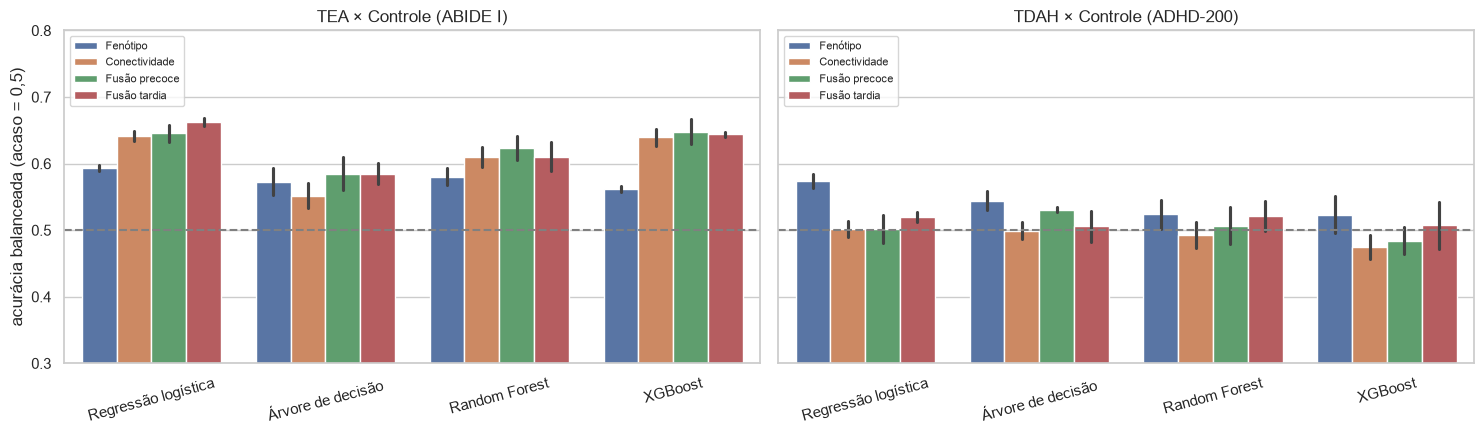

In [5]:
longo = pd.concat([r.assign(tarefa=k[0], modelo=k[1], conjunto=k[2]) for k, r in res.items()])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, t in zip(axes, TAREFAS):
    sns.barplot(data=longo[longo.tarefa == t], x="modelo", y="acc_balanceada", hue="conjunto", hue_order=CONJUNTOS,
                errorbar="sd", ax=ax)
    ax.axhline(0.5, ls="--", c="gray"); ax.set_ylim(0.3, 0.8); ax.set_title(t); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15); ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel("acurácia balanceada (acaso = 0,5)")
plt.tight_layout(); plt.savefig(FIG / "06_fusao_fenotipo_conectividade.png", dpi=150)

### A fusão melhora sobre a melhor fonte isolada?
Diferença pareada por semente (mesmas dobras) entre cada fusão e a melhor fonte isolada do mesmo modelo.
Com 3 repetições, só a média e o sinal da diferença são informativos.

In [6]:
linhas = []
for t in TAREFAS:
    for modelo in ["Regressão logística", "Árvore de decisão", "Random Forest", "XGBoost"]:
        iso = {c: res[(t, modelo, c)].acc_balanceada for c in ["Fenótipo", "Conectividade"]}
        melhor = max(iso, key=lambda c: iso[c].mean())
        for fus in ["Fusão precoce", "Fusão tardia"]:
            dif = res[(t, modelo, fus)].acc_balanceada.values - iso[melhor].values
            linhas.append({"tarefa": t, "modelo": modelo, "fusão": fus, "melhor isolada": melhor,
                           "acc fusão": res[(t, modelo, fus)].acc_balanceada.mean(),
                           "acc isolada": iso[melhor].mean(), "diferença": dif.mean()})
pd.DataFrame(linhas).round(3)

,tarefa,modelo,fusão,melhor isolada,acc fusão,acc isolada,diferença
0,TEA × Controle (ABIDE I),Regressão logística,Fusão precoce,Conectividade,0.646,0.641,0.005
1,TEA × Controle (ABIDE I),Regressão logística,Fusão tardia,Conectividade,0.662,0.641,0.021
2,TEA × Controle (ABIDE I),Árvore de decisão,Fusão precoce,Fenótipo,0.585,0.573,0.012
3,TEA × Controle (ABIDE I),Árvore de decisão,Fusão tardia,Fenótipo,0.585,0.573,0.012
4,TEA × Controle (ABIDE I),Random Forest,Fusão precoce,Conectividade,0.623,0.610,0.013
5,TEA × Controle (ABIDE I),Random Forest,Fusão tardia,Conectividade,0.610,0.610,0.000
6,TEA × Controle (ABIDE I),XGBoost,Fusão precoce,Conectividade,0.648,0.639,0.009
7,TEA × Controle (ABIDE I),XGBoost,Fusão tardia,Conectividade,0.644,0.639,0.005
8,TDAH × Controle (ADHD-200),Regressão logística,Fusão precoce,Fenótipo,0.502,0.574,-0.072
9,TDAH × Controle (ADHD-200),Regressão logística,Fusão tardia,Fenótipo,0.520,0.574,-0.053


## 3. Leitura dos resultados (execução de 25/11/2026)

Acurácia balanceada, média de 3 repetições (acaso = 0,50); entre parênteses, AUC.

**TEA × Controle (ABIDE I, 732 sujeitos, 17 instituições)**

| Modelo | Fenótipo | Conectividade | Fusão precoce | Fusão tardia |
|---|---|---|---|---|
| Regressão logística | 0,59 (0,62) | 0,64 (0,69) | 0,65 (0,69) | **0,66 (0,71)** |
| XGBoost | 0,56 (0,59) | 0,64 (0,69) | 0,65 (0,71) | 0,64 (0,69) |
| Random Forest | 0,58 (0,61) | 0,61 (0,67) | 0,62 (0,69) | 0,61 (0,65) |
| Árvore de decisão | 0,57 (0,59) | 0,55 (0,57) | 0,59 (0,60) | 0,59 (0,61) |

**TDAH × Controle (ADHD-200, 853 sujeitos, 7 instituições)**

| Modelo | Fenótipo | Conectividade | Fusão precoce | Fusão tardia |
|---|---|---|---|---|
| Regressão logística | **0,57 (0,59)** | 0,50 (0,49) | 0,50 (0,49) | 0,52 (0,53) |
| Árvore de decisão | 0,54 (0,52) | 0,50 (0,51) | 0,53 (0,53) | 0,51 (0,51) |
| Random Forest | 0,52 (0,54) | 0,49 (0,49) | 0,51 (0,51) | 0,52 (0,53) |
| XGBoost | 0,52 (0,51) | 0,48 (0,45) | 0,48 (0,48) | 0,51 (0,49) |

- **TEA × Controle:** fenótipo e conectividade se complementam. A fusão tardia com regressão logística dá o melhor
  resultado do projeto (**0,66, AUC 0,71**), +0,02 sobre a conectividade sozinha. Todas as fusões ficam iguais ou
  acima da melhor fonte isolada (+0,00 a +0,02), um ganho pequeno.
- **TDAH × Controle:** o sinal vem do **fenótipo** (QI: controles 114 × TDAH 106), não da conectividade. Juntar a
  conectividade **piora** o resultado (−0,02 a −0,07), porque ela só acrescenta ruído.
- **Comitês × árvore (hipótese do canvas):** em TEA × Controle, RF e XGBoost superam a árvore em todas as versões com
  conectividade (+0,03 a +0,09). Mas a regressão logística empata ou supera os comitês em todos os cenários.
- **Cuidado com o fenótipo:** o QI verbal e de execução falta mais nos controles do ADHD-200 (36%) que no TDAH (23%).
  A imputação iterativa evita um valor fixo que denuncie a ausência, mas parte da diferença pode vir do padrão de
  dados ausentes, e não do QI em si. Os testes de QI também diferem entre sítios.

**Conclusão:** para TEA, combinar fenótipo e conectividade ajuda pouco, mas de forma consistente; para TDAH, a
conectividade (com estes pipelines e validação entre instituições) não acrescenta nada ao QI.